<!-- repro-header -->
> **Reproducibility header**
>
> - **Aim:** Select the region of interest (ROI) of this dataset and save it as `rois/<dataset>/data.zarr` + `metadata.csv`.
> - **Manuscript panels:** Fig. 1A (dataset collection); input to all downstream analyses
> - **Inputs:** Raw vendor output in `rois/raw/`
> - **Outputs:** `rois/<dataset>/data.zarr`, `metadata.csv`
> - **Environment / kernel:** `troutpy_drvi`
> - Data root: `/lustre/groups/ml01/datasets/projects/2025_sergio_troutpy` (ROIs on Zenodo 10.5281/zenodo.17446348). 


# 1. Aim of the notebook

In this notebook we will select specific regions of interest to apply troutpy on, with the aim of characterizing the nature of transcripts outside segmented regions

## Import packages

In [1]:
import spatialdata_io
import spatialdata as sd
import troutpy
import scanpy as sc
from spatialdata import SpatialData
import matplotlib.pyplot as plt
from spatialdata.transformations import get_transformation
import matplotlib.patches as patches
import os
import numpy as np
import sys


from troutpy_reproducibility.roi_processing import *

/home/sergio/.local/lib/python3.10/site-packages/dask/dataframe/__init__.py:31: FutureWarning: The legacy Dask DataFrame implementation is deprecated and will be removed in a future version. Set the configuration option `dataframe.query-planning` to `True` or None to enable the new Dask Dataframe implementation and silence this warning.
  warnings.warn(
/home/sergio/.local/lib/python3.10/site-packages/numba/core/decorators.py:246: RuntimeWarning: nopython is set for njit and is ignored
  warnings.warn('nopython is set for njit and is ignored', RuntimeWarning)
/home/sergio/.local/lib/python3.10/site-packages/anndata/utils.py:429: FutureWarning: Importing read_text from `anndata` is deprecated. Import anndata.io.read_text instead.
  warnings.warn(msg, FutureWarning)
/home/sergio/.local/lib/python3.10/site-packages/anndata/utils.py:429: FutureWarning: Importing read_text from `anndata` is deprecated. Import anndata.io.read_text instead.
  warnings.warn(msg, FutureWarning)


## Read main path to .zarr file

In [2]:
inpath = "/media/sergio/Meninges/troutpy/raw/xenium_hs_prostate/Xenium_Prime_Human_Prostate_FFPE_outs"
sdata = spatialdata_io.xenium(inpath)

output_path = "/media/sergio/Meninges/troutpy/rois/xenium_hsprostate"

INFO     reading                                                                                                   
         /media/sergio/Meninges/troutpy/raw/xenium_hs_prostate/Xenium_Prime_Human_Prostate_FFPE_outs/cell_feature_m
         atrix.h5                                                                                                  


In [3]:
os.mkdir(output_path)

We decide to keep the data in a unified scale (um), which then can be transformated to 'global' coordinates using the according transformation. This global transformation is specially useful for matching the sales of transcripts with ie images

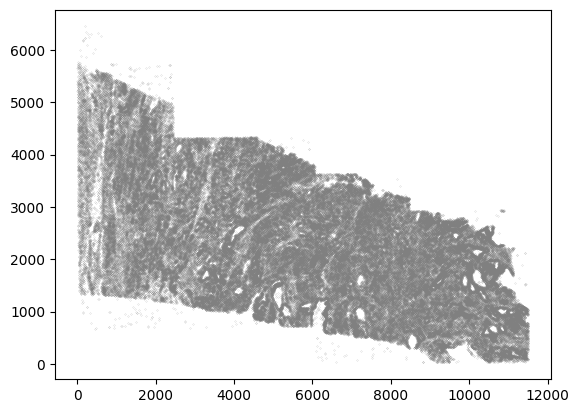

In [4]:
# Visualize using global coordinates
local_coords = sdata["table"].obsm["spatial"]
# In case it's needed, chec transformations
# print(  get_transformation(sdata["nucleus_boundaries"]))
spat = [g[0] for g in sdata["table"].obsm["spatial"]]
spat2 = [g[1] for g in sdata["table"].obsm["spatial"]]
plt.scatter(spat, spat2, s=0.01, c="grey")

In [5]:
# ROI selection
bb_xmin = 0  # mix x
bb_ymin = 10000  # min y
bb_xmax = 10099  # max x
bb_ymax = 14099.9  # max y

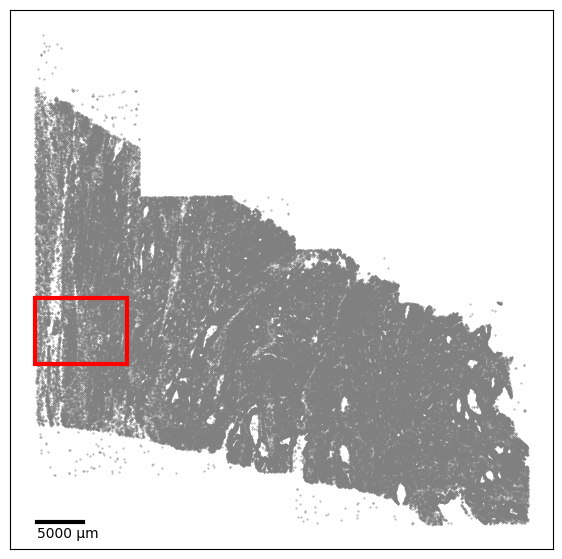

In [6]:
plot_spatial_with_box_and_scale(
    spatial_coords=sdata["table"].obsm["spatial"], bb_xmin=bb_xmin, bb_xmax=bb_xmax, bb_ymin=bb_ymin, bb_ymax=bb_ymax
)

Next, we select the ROI of interest

In [7]:
cropped_sdata = sdata.query.bounding_box(
    axes=["x", "y"],
    min_coordinate=[bb_xmin, bb_ymin],
    max_coordinate=[bb_xmax, bb_ymax],
    target_coordinate_system="global",
)

# Save metadata
metadata = generate_metadata(
    sdata=cropped_sdata,
    sample_id="human_prostate_5k",
    species="Homo Sapiens",
    technology="Xenium",
    segmentation_method="multimodal",
    roi_name="prostate",
    tissue="prostate",
    disease="prostate cancer",
)

rechunk_sdata(cropped_sdata)

Processing image: morphology_focus
  Rechunking scale: scale0
  Applying chunking...
  Rechunking scale: scale1
  Applying chunking...
  Rechunking scale: scale2
  Applying chunking...
  Rechunking scale: scale3
  Applying chunking...
  Rechunking scale: scale4
  Applying chunking...
Processing label: nucleus_labels
  Rechunking scale: scale0
  Applying chunking...
  Rechunking scale: scale1
  Applying chunking...
  Rechunking scale: scale2
  Applying chunking...
  Rechunking scale: scale3
  Applying chunking...
  Rechunking scale: scale4
  Applying chunking...
Processing label: cell_labels
  Rechunking scale: scale0
  Applying chunking...
  Rechunking scale: scale1
  Applying chunking...
  Rechunking scale: scale2
  Applying chunking...
  Rechunking scale: scale3
  Applying chunking...
  Rechunking scale: scale4
  Applying chunking...


In [14]:
cropped_sdata['morphology_focus']['scale0']

DataTree('scale0', parent="None")
    Dimensions:  (c: 5, y: 4100, x: 10099)
    Coordinates:
      * c        (c) <U22 440B 'DAPI' 'ATP1A1/CD45/E-Cadherin' ... 'dummy'
      * y        (y) float64 33kB 0.5 1.5 2.5 3.5 ... 4.098e+03 4.098e+03 4.1e+03
      * x        (x) float64 81kB 0.5 1.5 2.5 3.5 ... 1.01e+04 1.01e+04 1.01e+04
    Data variables:
        image    (c, y, x) uint16 414MB dask.array<chunksize=(1, 512, 512), meta=np.ndarray>

In [20]:
import copy

import numpy as np
import pandas as pd
import spatialdata as sd
import xarray as xr
from spatialdata.models import Image2DModel, Labels2DModel, TableModel


def xenium_converter(sdata, copy=False, unassigned_tag="UNASSIGNED"):
    """
    Converts a SpatialData object (sdata) into the Xenium format.

    The modifications performed are as follows:

    Points / Transcripts:
      - In sdata.Points['transcripts'] (a pandas DataFrame):
          * Rename the 'feature_name' column to 'Gene' and convert it to a categorical variable.
          * Create a boolean column 'control_probe' based on 'codeword_category':
                if the value is 'predesigned_gene' -> False;
                otherwise -> True.
          * Cast 'transcript_id' to a string and ensure the values are unique.
          * Cast 'overlaps_nucleus' to boolean.
          * Create a new column 'overlaps_cell' where if 'cell_id' == 'UNASSIGNED' then False, else True.

    Tables:
      - In sdata.Tables['table'] (an AnnData object):
          * Check that the .obs DataFrame contains a 'cell_id' column.
          * Ensure that the .obs index is unique.
          * Create a new layer named 'raw' in table.layers containing a copy of table.X (the raw expression data).

    Images:
      - From sdata.Images['morphology_focus'] (a DataTree of images at multiple resolutions):
          * Extract the highest quality image (scale 'scale0') and store it in sdata.Stainings under the key 'default'.

    Parameters
    ----------
    sdata : spatialdata.SpatialData
        A SpatialData object with attributes such as Images, Points, and Tables, conforming to the structure detailed in the SpatialData documentation.

    Returns
    -------
    sdata : spatialdata.SpatialData
        The converted SpatialData object with the modifications applied.
    """
    # ----- 1. Modify the Points/transcripts DataFrame -----
    try:
        transcripts = sdata["transcripts"].compute().reset_index(drop=True)
    except (KeyError, AttributeError) as e:
        raise ValueError("SpatialData must contain Points['transcripts'] as a DataFrame.") from e

    # a. Rename 'feature_name' to 'Gene' and convert to categorical
    if "feature_name" in transcripts.columns:
        transcripts = transcripts.rename(columns={"feature_name": "gene"})
        transcripts["gene"] = transcripts["gene"].astype("category")
    else:
        print("Warning: 'feature_name' column not found in Points['transcripts'].")

    # b. Create new boolean column 'control_probe' based on 'codeword_category'
    if "codeword_category" in transcripts.columns:
        transcripts["control_probe"] = transcripts["codeword_category"].apply(lambda x: False if x == "predesigned_gene" else True)
    else:
        print("Warning: 'codeword_category' column not found in Points['transcripts']. Gene name-based control probe assignment will be used.")
        transcripts["control_probe"] = transcripts["gene"].str.startswith(("Neg", "BLANK"))

    # c. Ensure 'transcript_id' is a string and has unique values.
    if "transcript_id" in transcripts.columns:
        transcripts["transcript_id"] = transcripts["transcript_id"].astype(str)
        if transcripts["transcript_id"].duplicated().any():
            raise ValueError("Duplicate values found in 'transcript_id'. They must be unique.")
    else:
        print("Warning: 'transcript_id' column not found in Points['transcripts'].")

    # d. Convert 'overlaps_nucleus' to boolean.
    if "overlaps_nucleus" in transcripts.columns:
        transcripts["overlaps_nucleus"] = transcripts["overlaps_nucleus"].astype(bool)
    else:
        print("Warning: 'overlaps_nucleus' column not found in Points['transcripts'].")

    # e. Create new 'overlaps_cell' boolean column based on 'cell_id'.
    if "cell_id" in transcripts.columns:
        transcripts["overlaps_cell"] = transcripts["cell_id"].apply(lambda x: False if x == unassigned_tag else True)
    else:
        print("Warning: 'cell_id' column not found in Points['transcripts']. Cannot create 'overlaps_cell'.")

    # Update the transcripts in Points
    sdata["transcripts"] = sd.models.PointsModel.parse(transcripts)

    # ----- 2. Modify the Tables object -----
    try:
        table = sdata["table"]
    except (KeyError, AttributeError) as e:
        raise ValueError("SpatialData must contain Tables['table'] as an AnnData object.") from e

    # Verify that table.obs contains the 'cell_id' column.
    if "cell_id" not in table.obs.columns:
        raise ValueError("Tables['table'].obs must contain a 'cell_id' column.")
    # Ensure the index is unique.
    if table.obs.index.duplicated().any():
        raise ValueError("Tables['table'].obs index contains duplicates. They must be unique.")
    # Create a new layer 'raw' storing a copy of table.X (raw expression data).
    try:
        table.var["gene_id"] = table.var.index
        table.var.index = table.var["gene_names"]
    except KeyError:
        print("Warning: 'gene_names' column not found in Tables['table']. Using default index.")
    if table.X is None:
        raise ValueError("Tables['table'] must have an expression matrix in .X.")
    if not hasattr(table, "layers") or table.layers is None:
        table.layers = {}
    table.layers["raw"] = table.X.copy()

    # ----- 3. Move Images to Stainings -----
    try:
        morph_focus = sdata["morphology_focus"]
    except (KeyError, AttributeError):
        print("Warning: SpatialData does not have Images['morphology_focus'].")
        morph_focus = None

    if morph_focus is not None:
        # Assume morph_focus is a DataTree (or similar dict-like object) with keys for different scales.
        if "scale0" in morph_focus:
            default_image = morph_focus["scale0"]
        else:
            print("Warning: 'scale0' not found in Images['morphology_focus']. Using first available scale.")
            default_image = next(iter(morph_focus.values()))

        # Create or update the Stainings attribute.
        # if not hasattr(sdata, "Stainings") or sdata.images is None:
        #    sdata.images = {}
        #sdata["default"] = default_image

    return sdata if copy else None

In [21]:
# troutpy converter to xenium
xenium_converter(cropped_sdata, unassigned_tag="UNASSIGNED")

In [ ]:
# Define output paths
zarr_path = os.path.join(output_path, "data.zarr")
metadata_path = os.path.join(output_path, "metadata.csv")

cropped_sdata.write(zarr_path, overwrite=True)
metadata.to_csv(metadata_path, index=False)